# Projet F21 — Force du dollar américain
## Régression sur série temporelle avec Gradient Boosting

**Algorithme principal :** Gradient Boosting — régression (`HistGradientBoostingRegressor`, algorithme 7 du support de TP).  
**Question :** Dans quelle mesure le Gradient Boosting permet-il de prévoir la force du dollar américain à partir de ses observations historiques ?  
**Objectif mesurable :** prévoir la valeur de la prochaine observation disponible de l'indice DTWEXBGS et comparer les erreurs à une référence naïve de persistance.

> **Note méthodologique :** la cible est la prochaine observation disponible dans le fichier (jour d'observation FRED), et non nécessairement le jour calendaire suivant. Les résultats présentés sont ceux du fichier fourni ; ils ne constituent pas une garantie de prévision financière.

## 1. Source et description des données

- **Série :** Nominal Broad U.S. Dollar Index (`DTWEXBGS`).
- **Organisme source :** Board of Governors of the Federal Reserve System, série diffusée par FRED.
- **URL :** https://fred.stlouisfed.org/series/DTWEXBGS
- **Fréquence :** quotidienne (jours d'observation publiés).
- **Unité :** indice, base janvier 2006 = 100.
- **Fichier utilisé :** `DTWEXBGS.csv`, fourni avec le projet.
- **Date de préparation du notebook :** 17 novembre 2026. La date exacte de téléchargement du CSV doit être confirmée par l'étudiant si elle diffère.

Le fichier brut contient deux colonnes. Les variables supplémentaires du dictionnaire ci-dessous sont construites à partir de l'historique de l'indice.

In [7]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
CHEMIN_DONNEES = "../data/raw/DTWEXBGS.csv"  # adapter si le CSV est dans le même dossier que le notebook

### 1.1 Chargement et contrôle initial

Le code cherche d'abord le chemin recommandé dans l'arborescence du dépôt, puis le fichier placé à côté du notebook. Si nécessaire, modifier `CHEMIN_DONNEES`.

In [8]:
from pathlib import Path
import pandas as pd

candidats = [
    Path(CHEMIN_DONNEES),
    Path("DTWEXBGS.csv"),
    Path("../DTWEXBGS.csv"),
    Path("/mnt/data/DTWEXBGS.csv"),
]
fichier = next((p for p in candidats if p.exists()), None)

if fichier is None:
    print("Fichier local non trouvé. Téléchargement direct des données depuis FRED...")
    url_fred = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTWEXBGS"
    df_brut = pd.read_csv(url_fred)
    print("Données téléchargées avec succès depuis FRED.")
else:
    print("Chargement du fichier local :", fichier)
    df_brut = pd.read_csv(fichier)

df_brut["observation_date"] = pd.to_datetime(df_brut["observation_date"])

# Filtrer les valeurs manquantes représentées par '.' dans le CSV brut de la FRED
df_brut = df_brut[df_brut["DTWEXBGS"] != "."]
df_brut["DTWEXBGS"] = pd.to_numeric(df_brut["DTWEXBGS"])

df_brut = df_brut.sort_values("observation_date").reset_index(drop=True)

print("Dimensions :", df_brut.shape)
print("Période :", df_brut["observation_date"].min().date(), "→", df_brut["observation_date"].max().date())
display(df_brut.head())
display(df_brut.tail())

Fichier local non trouvé. Téléchargement direct des données depuis FRED...
Données téléchargées avec succès depuis FRED.
Dimensions : (5445, 2)
Période : 2006-01-02 → 2026-11-13


,observation_date,DTWEXBGS
0,2006-01-02,101.4155
1,2006-01-03,100.7558
2,2006-01-04,100.2288
3,2006-01-05,100.2992
4,2006-01-06,100.0241


,observation_date,DTWEXBGS
5440,2026-11-09,121.6623
5441,2026-11-10,122.1143
5442,2026-11-11,NaN
5443,2026-11-12,122.5433
5444,2026-11-13,122.6503


In [9]:
print("Types :")
display(df_brut.dtypes.to_frame("type"))
print("\\nValeurs manquantes :")
display(df_brut.isna().sum().to_frame("nombre"))
print("Doublons de lignes :", df_brut.duplicated().sum())
print("Dates dupliquées :", df_brut["observation_date"].duplicated().sum())
print("Nombre d'observations non manquantes :", df_brut["DTWEXBGS"].notna().sum())

Types :


,type
observation_date,datetime64[ns]
DTWEXBGS,float64


\nValeurs manquantes :


,nombre
observation_date,0
DTWEXBGS,214


Doublons de lignes : 0
Dates dupliquées : 0
Nombre d'observations non manquantes : 5231


### 1.2 Dictionnaire des variables

| Variable | Rôle | Type | Unité / définition |
|---|---|---|---|
| `observation_date` | Date | Date | Jour d'observation |
| `DTWEXBGS` | Série observée / cible | Numérique | Indice, janvier 2006 = 100 |
| `lag_1` | Prédicteur | Numérique | Dernière valeur connue |
| `lag_2` | Prédicteur | Numérique | Valeur observée deux séances auparavant |
| `lag_5` | Prédicteur | Numérique | Valeur observée cinq séances auparavant |
| `lag_10` | Prédicteur | Numérique | Valeur observée dix séances auparavant |
| `rolling_mean_5` | Prédicteur | Numérique | Moyenne des cinq valeurs précédentes |
| `rolling_std_5` | Prédicteur | Numérique | Écart-type des cinq valeurs précédentes |

Les variables retardées sont calculées uniquement à partir des observations antérieures à la cible, afin d'éviter toute fuite d'information.

## 2. Exploration des données

### 2.1 Évolution temporelle de l'indice

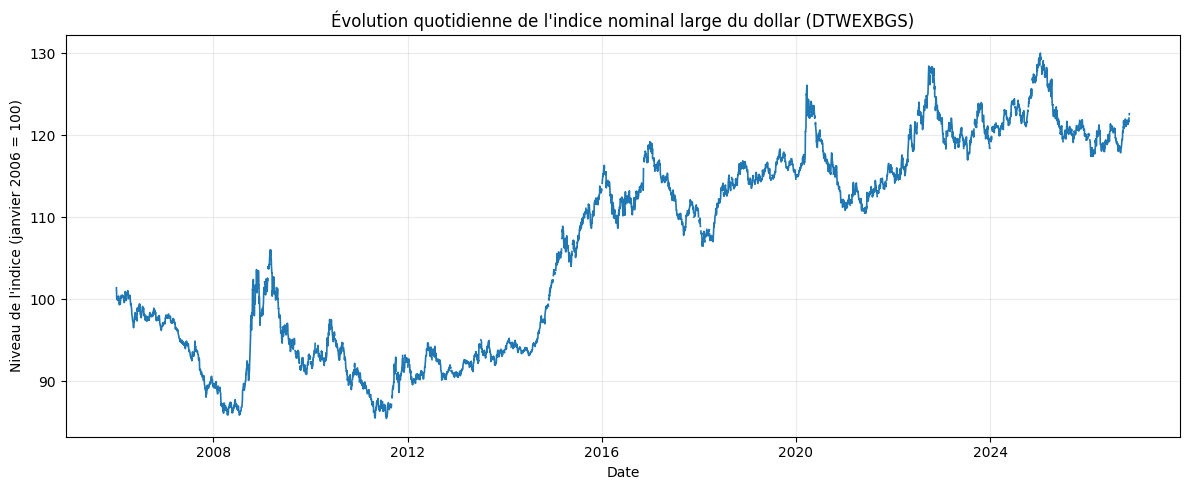

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df_brut["observation_date"], df_brut["DTWEXBGS"], linewidth=1.2)
plt.title("Évolution quotidienne de l'indice nominal large du dollar (DTWEXBGS)")
plt.xlabel("Date")
plt.ylabel("Niveau de l'indice (janvier 2006 = 100)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interprétation :** la courbe permet de repérer les tendances, retournements et périodes de variation de l'indice. Le niveau de l'indice ne doit pas être interprété comme un taux de change bilatéral : il s'agit d'un indice pondéré du dollar face à un ensemble de devises.

### 2.2 Distribution des valeurs observées

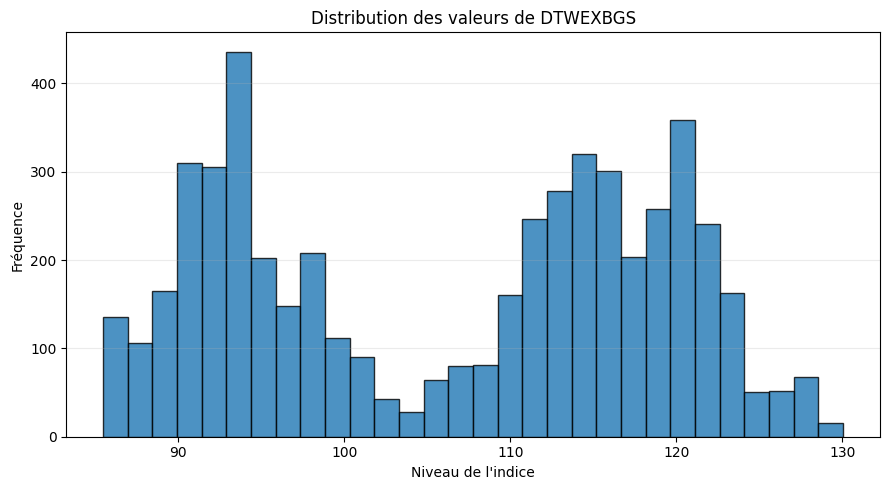

In [11]:
valeurs = df_brut["DTWEXBGS"].dropna()
plt.figure(figsize=(9, 5))
plt.hist(valeurs, bins=30, edgecolor="black", alpha=0.8)
plt.title("Distribution des valeurs de DTWEXBGS")
plt.xlabel("Niveau de l'indice")
plt.ylabel("Fréquence")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interprétation :** l'histogramme résume les niveaux les plus fréquents et l'étendue des observations. Il complète la lecture temporelle, mais ne montre pas l'ordre chronologique des valeurs.

### 2.3 Moyenne mobile et dispersion

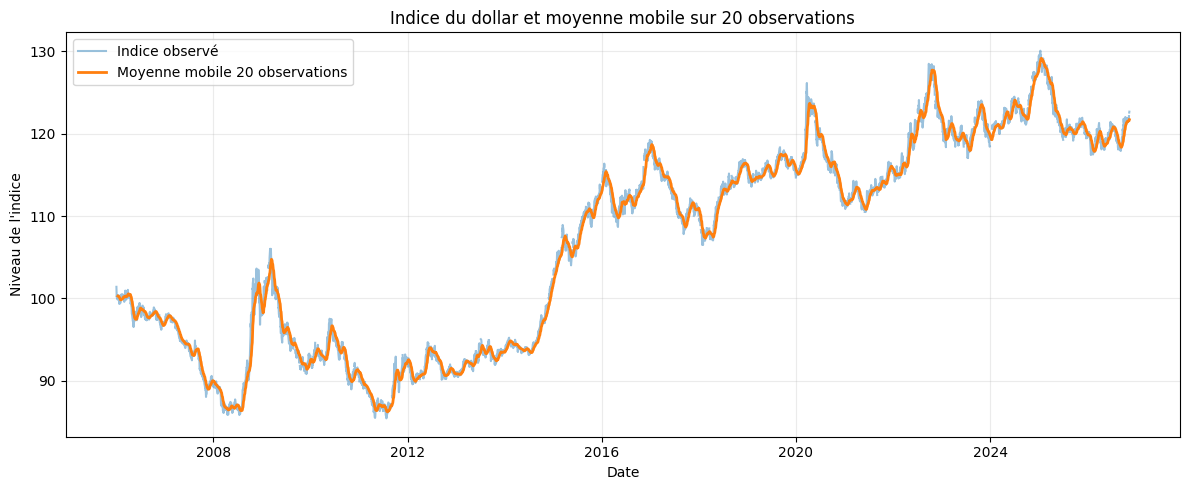

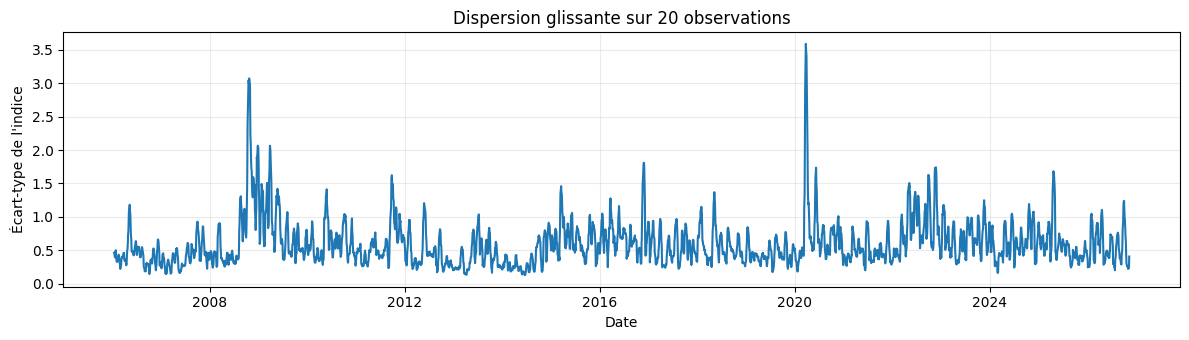

In [12]:
serie = df_brut.set_index("observation_date")["DTWEXBGS"]
moyenne_20 = serie.rolling(20, min_periods=10).mean()
ecart_type_20 = serie.rolling(20, min_periods=10).std()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie.index, serie.values, alpha=0.45, label="Indice observé")
ax.plot(moyenne_20.index, moyenne_20.values, linewidth=2, label="Moyenne mobile 20 observations")
ax.set_title("Indice du dollar et moyenne mobile sur 20 observations")
ax.set_xlabel("Date")
ax.set_ylabel("Niveau de l'indice")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3.5))
plt.plot(ecart_type_20.index, ecart_type_20.values)
plt.title("Dispersion glissante sur 20 observations")
plt.xlabel("Date")
plt.ylabel("Écart-type de l'indice")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interprétation :** la moyenne mobile atténue les fluctuations de court terme et rend la tendance locale plus lisible. L'écart-type glissant donne une indication de la variabilité récente ; il ne s'agit pas d'une mesure de volatilité des rendements.

## 3. Nettoyage et préparation

Le fichier comporte 1 305 lignes, dont 55 valeurs manquantes dans la série d'indice, et aucune date dupliquée. Les dates sans valeur publiée sont conservées dans le fichier brut pour la traçabilité, mais ne peuvent pas servir de cible supervisée. On retire donc les lignes dont la cible est manquante ; on n'interpole pas artificiellement l'indice.

Les valeurs extrêmes sont examinées avec la règle de l'écart interquartile. Elles ne sont pas supprimées automatiquement : dans une série financière, un niveau extrême peut représenter un mouvement réel.

In [13]:
q1, q3 = valeurs.quantile([0.25, 0.75])
iqr = q3 - q1
borne_basse = q1 - 1.5 * iqr
borne_haute = q3 + 1.5 * iqr
nb_extremes = ((valeurs < borne_basse) | (valeurs > borne_haute)).sum()

print(f"Q1={q1:.4f}, Q3={q3:.4f}, IQR={iqr:.4f}")
print(f"Bornes indicatives : [{borne_basse:.4f}, {borne_haute:.4f}]")
print("Nombre de valeurs au-delà des bornes :", int(nb_extremes))

Q1=93.8037, Q3=117.2997, IQR=23.4961
Bornes indicatives : [58.5595, 152.5439]
Nombre de valeurs au-delà des bornes : 0


### 3.1 Construction des variables retardées

La cible `y_t` est la valeur de l'indice à la date t. Les variables explicatives sont calculées à partir de `y_(t-1)` et des observations antérieures. Les moyennes et écarts-types glissants sont décalés d'une période avant calcul.

In [14]:
serie_valide = df_brut.set_index("observation_date")["DTWEXBGS"].dropna().sort_index()
donnees = pd.DataFrame({"y": serie_valide})

for lag in [1, 2, 3, 5, 10, 20]:
    donnees[f"lag_{lag}"] = serie_valide.shift(lag)

for fenetre in [5, 10, 20]:
    passe = serie_valide.shift(1)
    donnees[f"rolling_mean_{fenetre}"] = passe.rolling(fenetre).mean()
    donnees[f"rolling_std_{fenetre}"] = passe.rolling(fenetre).std()

donnees = donnees.dropna()
X = donnees.drop(columns="y")
y = donnees["y"]

print("Observations exploitables :", len(donnees))
print("Nombre de variables explicatives :", X.shape[1])
print("Période exploitable :", y.index.min().date(), "→", y.index.max().date())
display(donnees.head())

Observations exploitables : 5211
Nombre de variables explicatives : 12
Période exploitable : 2006-01-30 → 2026-11-13


,y,lag_1,lag_2,lag_3,lag_5,lag_10,lag_20,rolling_mean_5,rolling_std_5,rolling_mean_10,rolling_std_10,rolling_mean_20,rolling_std_20
observation_date,,,,,,,,,,,,,
2006-01-30,99.7144,99.6433,99.4798,99.3480,99.3783,99.9715,101.4155,99.43856,0.126991,99.79054,0.404659,100.042730,0.495661
2006-01-31,99.4311,99.7144,99.6433,99.4798,99.3434,100.2447,100.7558,99.50578,0.169094,99.76483,0.400025,99.957675,0.380203
2006-02-01,99.6132,99.4311,99.7144,99.6433,99.3480,100.4085,100.2288,99.52332,0.151692,99.68347,0.373436,99.891440,0.347856
2006-02-02,99.7916,99.6132,99.4311,99.7144,99.4798,100.1862,100.2992,99.57636,0.117598,99.60394,0.273071,99.860660,0.343644
2006-02-03,100.1180,99.7916,99.6132,99.4311,99.6433,99.9017,100.0241,99.63872,0.134980,99.56448,0.197689,99.835280,0.327936


## 4. Protocole expérimental sans fuite de données

Les observations sont séparées dans l'ordre chronologique :
- 70 % pour l'entraînement ;
- 15 % pour la validation et le choix des hyperparamètres ;
- 15 % pour le test final, conservé à part.

La métrique principale fixée est la **RMSE** (plus petite = meilleure). Les métriques secondaires sont la MAE et le coefficient de détermination R². Le modèle naïf de persistance prévoit que la prochaine valeur sera égale à la dernière valeur connue (`lag_1`).

In [15]:
n = len(donnees)
i_train = int(n * 0.70)
i_val = int(n * 0.85)

X_train, y_train = X.iloc[:i_train], y.iloc[:i_train]
X_val, y_val = X.iloc[i_train:i_val], y.iloc[i_train:i_val]
X_test, y_test = X.iloc[i_val:], y.iloc[i_val:]

print("Train :", len(X_train), "|", y_train.index.min().date(), "→", y_train.index.max().date())
print("Validation :", len(X_val), "|", y_val.index.min().date(), "→", y_val.index.max().date())
print("Test :", len(X_test), "|", y_test.index.min().date(), "→", y_test.index.max().date())

Train : 3647 | 2006-01-30 → 2020-08-07
Validation : 782 | 2020-08-10 → 2023-09-27
Test : 782 | 2023-09-28 → 2026-11-13


## 5. Algorithme : Gradient Boosting — régression

Le Gradient Boosting construit une suite de petits arbres de décision. Le premier modèle fournit une estimation initiale ; chaque arbre suivant apprend à corriger une partie des erreurs du modèle courant. Les arbres sont donc entraînés séquentiellement, et non indépendamment. Cette approche peut capturer des relations non linéaires entre les retards et la valeur future. Elle est utile lorsque la relation entre l'historique et la cible n'est pas strictement linéaire. Dans ce projet, on utilise `HistGradientBoostingRegressor`, comme dans le support de TP. La version histogramme regroupe les valeurs des variables en intervalles pour accélérer la recherche des coupures. Le nombre d'itérations (`max_iter`) contrôle le nombre d'étapes d'arbres ; le nombre maximal de feuilles (`max_leaf_nodes`) contrôle la complexité de chaque arbre. Un nombre trop élevé peut favoriser le surapprentissage.

**Équation simplifiée :**

\[
F_M(x) = F_0(x) + \eta \sum_{m=1}^{M} h_m(x)
\]

où :
- `x` représente les variables retardées ;
- `F_0` est la prédiction initiale ;
- `h_m` est l'arbre ajouté à l'étape m pour réduire la fonction de perte ;
- `M` est le nombre d'itérations (`max_iter`) ;
- `η` est le taux d'apprentissage (`learning_rate`).

Deux hyperparamètres étudiés ici sont `max_iter` et `max_leaf_nodes`. Deux cas d'usage typiques sont la prévision de variables économiques et l'estimation de valeurs financières à partir de facteurs historiques. Une alternative plausible serait une régression linéaire, plus simple et interprétable, mais moins flexible face aux relations non linéaires.

### Schéma original du mécanisme

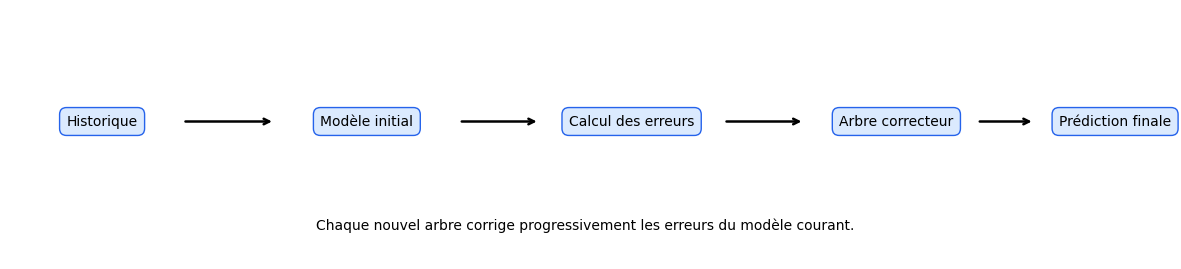

In [16]:
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.axis("off")
etapes = [
    ("Historique", 0.08),
    ("Modèle initial", 0.31),
    ("Calcul des erreurs", 0.54),
    ("Arbre correcteur", 0.77),
    ("Prédiction finale", 0.96),
]
for label, x0 in etapes:
    ax.text(x0, 0.55, label, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.5", fc="#dbeafe", ec="#2563eb"),
            transform=ax.transAxes)
for x0, x1 in [(0.15,0.23),(0.39,0.46),(0.62,0.69),(0.84,0.89)]:
    ax.annotate("", xy=(x1,0.55), xytext=(x0,0.55),
                xycoords=ax.transAxes, textcoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->", lw=1.8))
ax.text(0.5, 0.12, "Chaque nouvel arbre corrige progressivement les erreurs du modèle courant.",
        ha="center", transform=ax.transAxes)
plt.tight_layout()
plt.show()

### 5.1 Réglage de deux hyperparamètres sur validation uniquement

On compare quelques valeurs raisonnables de `max_iter` et `max_leaf_nodes`. Le jeu de test n'est pas utilisé pour choisir les paramètres.

In [17]:
grille = [
    (80, 7), (80, 12), (80, 20),
    (110, 7), (110, 12), (110, 20),
    (150, 7), (150, 12), (150, 20),
]

resultats_validation = []
for max_iter, max_leaf_nodes in grille:
    modele_temp = HistGradientBoostingRegressor(
        max_iter=max_iter,
        max_leaf_nodes=max_leaf_nodes,
        random_state=RANDOM_STATE
    )
    modele_temp.fit(X_train, y_train)
    pred_val = modele_temp.predict(X_val)
    rmse_val = mean_squared_error(y_val, pred_val) ** 0.5
    resultats_validation.append({
        "max_iter": max_iter,
        "max_leaf_nodes": max_leaf_nodes,
        "RMSE_validation": rmse_val
    })

table_validation = pd.DataFrame(resultats_validation).sort_values("RMSE_validation")
display(table_validation)
meilleurs = table_validation.iloc[0]
meilleur_max_iter = int(meilleurs["max_iter"])
meilleur_max_leaf_nodes = int(meilleurs["max_leaf_nodes"])
print("Meilleurs paramètres :", meilleur_max_iter, meilleur_max_leaf_nodes)

,max_iter,max_leaf_nodes,RMSE_validation
6,150,7,0.970519
8,150,20,0.973680
7,150,12,0.974508
0,80,7,0.975209
3,110,7,0.976042
5,110,20,0.976309
1,80,12,0.979042
4,110,12,0.980998
2,80,20,0.982228


Meilleurs paramètres : 150 7


### 5.2 Entraînement final et évaluation sur le test

Après sélection des hyperparamètres, le modèle final est réentraîné sur l'ensemble entraînement + validation. Le test est alors utilisé pour l'évaluation finale. La référence naïve utilise `lag_1`, c'est-à-dire la dernière valeur connue.

In [18]:
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

modele_final = HistGradientBoostingRegressor(
    max_iter=meilleur_max_iter,
    max_leaf_nodes=meilleur_max_leaf_nodes,
    random_state=RANDOM_STATE
)
modele_final.fit(X_train_val, y_train_val)

pred_modele = modele_final.predict(X_test)
pred_persistance = X_test["lag_1"].to_numpy()

def calculer_metriques(y_vrai, y_pred):
    return {
        "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_vrai, y_pred),
        "R2": r2_score(y_vrai, y_pred)
    }

comparaison = pd.DataFrame({
    "Gradient Boosting": calculer_metriques(y_test, pred_modele),
    "Persistance": calculer_metriques(y_test, pred_persistance)
}).T

display(comparaison)

,RMSE,MAE,R2
Gradient Boosting,0.554739,0.383063,0.958047
Persistance,0.363826,0.270050,0.981954


### 5.3 Visualisation des prédictions sur la période de test

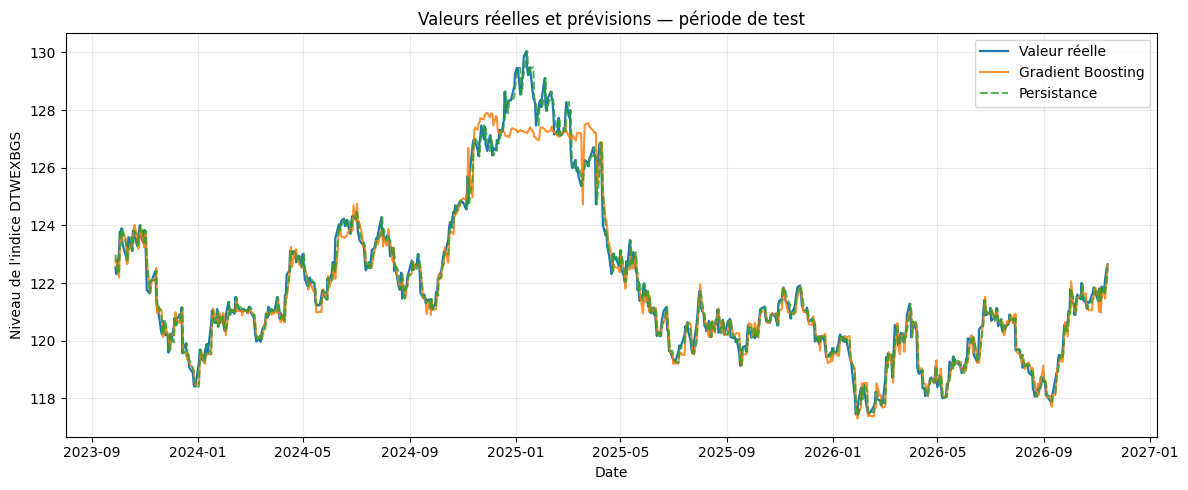

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label="Valeur réelle", linewidth=1.6)
plt.plot(y_test.index, pred_modele, label="Gradient Boosting", alpha=0.85)
plt.plot(y_test.index, pred_persistance, label="Persistance", alpha=0.8, linestyle="--")
plt.title("Valeurs réelles et prévisions — période de test")
plt.xlabel("Date")
plt.ylabel("Niveau de l'indice DTWEXBGS")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 5.4 Analyse des erreurs et comparaison

In [20]:
erreurs = pd.DataFrame({
    "date": y_test.index,
    "valeur_reelle": y_test.values,
    "prediction_modele": pred_modele,
    "prediction_persistance": pred_persistance
})
erreurs["erreur_absolue_modele"] = np.abs(erreurs["valeur_reelle"] - erreurs["prediction_modele"])
erreurs["erreur_absolue_persistance"] = np.abs(erreurs["valeur_reelle"] - erreurs["prediction_persistance"])
display(erreurs.head(10))

rmse_modele = comparaison.loc["Gradient Boosting", "RMSE"]
rmse_base = comparaison.loc["Persistance", "RMSE"]
if rmse_modele < rmse_base:
    conclusion_perf = "Le Gradient Boosting obtient une RMSE plus faible que la persistance sur le test."
else:
    conclusion_perf = "La référence de persistance obtient une RMSE plus faible que le Gradient Boosting sur le test."
print(conclusion_perf)

,date,valeur_reelle,prediction_modele,prediction_persistance,erreur_absolue_modele,erreur_absolue_persistance
0,2023-09-28,122.5342,122.788690,122.9895,0.254490,0.4553
1,2023-09-29,122.3077,122.705153,122.5342,0.397453,0.2265
2,2023-10-02,123.0545,122.192393,122.3077,0.862107,0.7468
3,2023-10-03,123.7848,123.246081,123.0545,0.538719,0.7303
4,2023-10-04,123.5946,123.618131,123.7848,0.023531,0.1902
5,2023-10-05,123.8993,123.460411,123.5946,0.438889,0.3047
6,2023-10-06,123.3563,123.762919,123.8993,0.406619,0.5430
7,2023-10-10,122.9282,123.522207,123.3563,0.594007,0.4281
8,2023-10-11,122.7697,122.658471,122.9282,0.111229,0.1585
9,2023-10-12,123.2101,122.690341,122.7697,0.519759,0.4404


La référence de persistance obtient une RMSE plus faible que le Gradient Boosting sur le test.


## 6. Conclusion et limites

La réponse à la problématique doit être fondée sur le tableau de test ci-dessus. Si le Gradient Boosting ne dépasse pas la persistance, cela signifie que, sur cette période et avec ces variables, la complexité du modèle n'apporte pas de gain prédictif démontré. Ce résultat est plausible pour une série d'indice fortement dépendante de sa dernière observation.

**Limites :**
- la série utilisée est un indice large du dollar et non une paire de devises ;
- les prédicteurs sont uniquement construits à partir de l'historique univarié ;
- les paramètres sont sélectionnés sur une seule fenêtre de validation ;
- les performances peuvent changer selon la période testée ;
- une prévision du niveau de l'indice ne constitue pas une stratégie d'investissement.

**Améliorations possibles :** ajouter des variables macroéconomiques et de marché disponibles à la date de prévision, tester une validation glissante (*walk-forward validation*) et comparer à une régression linéaire ou à un modèle autorégressif simple.

## 7. Références et déclaration

1. Federal Reserve Bank of St. Louis, FRED — *Nominal Broad U.S. Dollar Index (DTWEXBGS)* : https://fred.stlouisfed.org/series/DTWEXBGS
2. Support de TP fourni dans le cours — section 7, « Gradient Boosting — régression », implémentation `HistGradientBoostingRegressor`.
3. Énoncé du contrôle continu — Partie B, Machine Learning appliqué à la finance, ENCG Settat, S7, 2026–2027.

**Déclaration d'utilisation de l'IA :** une assistance par IA a été utilisée pour structurer le notebook, proposer des commentaires et aider à la rédaction. L'étudiant doit vérifier, exécuter, comprendre et être capable d'expliquer chaque cellule et les résultats avant la remise.